# Days of survival in the NCCTG lung cancer trial

A clinic that has just enrolled a patient with advanced lung cancer can see age, sex, and the physician's ECOG performance score. It cannot see how many days are left. The trial followed 228 patients from the North Central Cancer Treatment Group. Time is days from enrollment. In the source file a status of 1 is censored and 2 is dead, which is the coding in R's `survival` package, not a 0/1 event indicator.

The file is that table, retrieved 2026-10-04 from the Rdatasets mirror of `survival::cancer`: `https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/survival/cancer.csv`. The study is Loprinzi and colleagues, Journal of Clinical Oncology 1994, the NCCTG lung cancer data distributed with the survival package. One patient has no ECOG score and is dropped. Calories and weight loss are missing for many patients and are not used. Institution is not a patient characteristic the clinic will have for the next referral.

The decision is which survival distribution to quote. A Weibull accelerated-failure-time model is the usual parametric choice. A lognormal and a log-logistic allow a hazard that is not monotone. A Cox model ranks patients and does not by itself name a distribution of days. An ordinary regression of log days, fit on the deaths only, is the baseline that throws away the censored patients. Steps for the boosts are chosen on held-out patients, stratified by whether the death was observed.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | days from enrollment until death |
| **Observed response** | follow-up time, censored if the patient was alive at last contact |
| **Estimand** | mean negative log likelihood of the censored log-time, and Harrell's concordance |
| **Units** | nats per patient on the log-day scale; concordance is a probability |
| **Sampling unit** | one row is one patient with a follow-up time and censoring indicator |
| **Dependence** | The working survival models assume conditionally independent patient outcomes and censoring; no shared frailty is estimated. |
| **Split and tuning** | patients, stratified by event; 25% choose steps, 25% held out, refit on the rest |
| **Information** | age in years, female (male is the reference), ECOG score as recorded (0 to 3) |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | a treatment effect, a cause of death, or a survival time for a patient whose ECOG score is missing |

The log-time likelihood is the one these accelerated-failure-time families optimise. It is not a density on the day scale, because that density would divide by the time. Cox partial likelihood is a different object and is not entered in the log-score column.

:::


In [1]:
import warnings
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.duration.hazard_regression import PHReg

import mboostrs as mb

csv_path = Path("ncctg_lung.csv")
if not csv_path.exists():
    csv_path = Path("docs/book/case_studies/ncctg_lung.csv")
raw = pl.read_csv(csv_path, comment_prefix="#")
dropped = int(raw["ph.ecog"].null_count())
frame = raw.drop_nulls(["ph.ecog"]).with_columns(
    (pl.col("status") == 2).cast(pl.Float64).alias("event"),
    (pl.col("sex") == 2).cast(pl.Float64).alias("female"),
    pl.col("time").cast(pl.Float64),
    pl.col("age").cast(pl.Float64),
    pl.col("ph.ecog").cast(pl.Float64).alias("ecog"),
)
formula = "Surv(time, event) ~ age + female + ecog"

rng = np.random.default_rng(20261004)
indexed = frame.with_row_index("i")
parts = []
for flag in (0.0, 1.0):
    ids = indexed.filter(pl.col("event") == flag)["i"].to_numpy().copy()
    rng.shuffle(ids)
    n = len(ids)
    n_test = int(round(0.25 * n))
    n_valid = int(round(0.25 * n))
    parts.append((ids[n_test + n_valid :], ids[n_test : n_test + n_valid], ids[:n_test]))
train_ids = np.concatenate([p[0] for p in parts])
valid_ids = np.concatenate([p[1] for p in parts])
test_ids = np.concatenate([p[2] for p in parts])
train = frame[train_ids.tolist()]
valid = frame[valid_ids.tolist()]
fit_rows = frame[np.concatenate([train_ids, valid_ids]).tolist()]
test = frame[test_ids.tolist()]
print(
    f"{raw.height} patients, {dropped} missing ECOG dropped, {frame.height} analysed, "
    f"{int(frame['event'].sum())} deaths, {int((frame['event'] == 0).sum())} censored; "
    f"{train.height} to fit the path, {valid.height} to choose steps, "
    f"{fit_rows.height} refit, {test.height} held out"
)


228 patients, 1 missing ECOG dropped, 227 analysed, 164 deaths, 63 censored; 113 to fit the path, 57 to choose steps, 170 refit, 57 held out


In [2]:
def nll_weibull(time, event, mu, sig):
    z = (np.log(time) - mu) / sig
    ll = event * (np.log(1.0 / sig) + z - np.exp(z)) + (1.0 - event) * (-np.exp(z))
    return float(-np.mean(ll))


def nll_lognormal(time, event, mu, sig):
    z = (np.log(time) - mu) / sig
    ll = event * (stats.norm.logpdf(z) - np.log(sig)) + (1.0 - event) * stats.norm.logsf(z)
    return float(-np.mean(ll))


def nll_loglog(time, event, mu, sig):
    z = (np.log(time) - mu) / sig
    log_f = -z - 2.0 * np.log1p(np.exp(-z)) - np.log(sig)
    log_s = -np.log1p(np.exp(z))
    return float(-np.mean(event * log_f + (1.0 - event) * log_s))


def c_index(time, event, risk):
    """Harrell's concordance. A larger risk means a shorter survival."""
    time = np.asarray(time, dtype=float)
    event = np.asarray(event, dtype=float)
    risk = np.asarray(risk, dtype=float)
    earlier = time[:, None]
    later = time[None, :]
    died = event[:, None] == 1.0
    comparable = died & (earlier < later)
    higher = risk[:, None]
    lower = risk[None, :]
    concordant = np.sum(comparable & (higher > lower))
    tied = np.sum(comparable & (higher == lower))
    return float((concordant + 0.5 * tied) / np.sum(comparable))


NLL = {"weibull": nll_weibull, "lognormal": nll_lognormal, "loglog": nll_loglog}


In [3]:
def choose_mstop(kind, cap):
    family = {"weibull": mb.Weibull(), "lognormal": mb.Lognormal(), "loglog": mb.Loglog(), "cox": mb.CoxPH()}[kind]
    path = mb.glmboost(formula, train, family=family, control=mb.boost_control(cap, 0.1))
    y_time = valid["time"].to_numpy()
    y_event = valid["event"].to_numpy()
    best_step, best_score = None, np.inf
    for step in range(10, cap + 1, 10):
        tuned = path.with_mstop(step)
        link = np.asarray(tuned.predict(valid, type="link"), dtype=float).ravel()
        if kind == "cox":
            score = -c_index(y_time, y_event, link)
        else:
            sig = float(np.asarray(tuned.nuisance()).ravel()[0])
            score = NLL[kind](y_time, y_event, link, sig)
        if score < best_score:
            best_step, best_score = step, score
    return best_step, best_score, best_step == cap


jobs = [
    ("mboostrs glmboost Weibull", "weibull", 200),
    ("mboostrs glmboost Lognormal", "lognormal", 200),
    ("mboostrs glmboost Loglog", "loglog", 200),
    ("mboostrs glmboost CoxPH", "cox", 200),
]
boosted = {}
for label, kind, cap in jobs:
    step, score, at_cap = choose_mstop(kind, cap)
    family = {"weibull": mb.Weibull(), "lognormal": mb.Lognormal(), "loglog": mb.Loglog(), "cox": mb.CoxPH()}[kind]
    fitted = mb.glmboost(formula, fit_rows, family=family, control=mb.boost_control(step, 0.1))
    boosted[label] = {
        "kind": kind,
        "mstop": step,
        "at_cap": at_cap,
        "fit": fitted,
        "link": np.asarray(fitted.predict(test, type="link"), dtype=float).ravel(),
    }


In [4]:
x_fit = fit_rows.select(["age", "female", "ecog"]).to_numpy()
x_test = test.select(["age", "female", "ecog"]).to_numpy()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    phreg = PHReg(
        fit_rows["time"].to_numpy(), x_fit, status=fit_rows["event"].to_numpy()
    ).fit(disp=False)
ph_pred = phreg.predict(exog=x_test, pred_type="lhr")
ph_link = np.asarray(getattr(ph_pred, "predicted_values", ph_pred), dtype=float).ravel()

deaths = fit_rows.filter(pl.col("event") == 1)
x_deaths = sm.add_constant(deaths.select(["age", "female", "ecog"]).to_numpy())
ols = sm.OLS(np.log(deaths["time"].to_numpy()), x_deaths).fit()
ols_sd = float(np.std(np.log(deaths["time"].to_numpy()) - ols.fittedvalues, ddof=0))
ols_mu = np.asarray(ols.predict(sm.add_constant(x_test)), dtype=float)

t_test = test["time"].to_numpy()
e_test = test["event"].to_numpy()
rows = []


def add(method, nll, concordance, mstop=None, at_cap=None, note=""):
    rows.append({
        "method": method,
        "nll": nll,
        "c_index": concordance,
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add(
    "statsmodels PHReg",
    None,
    c_index(t_test, e_test, ph_link),
    note="Cox; partial likelihood is not the log-time score",
)
add(
    "statsmodels OLS on deaths",
    nll_lognormal(t_test, e_test, ols_mu, ols_sd),
    c_index(t_test, e_test, -ols_mu),
    note=f"log sd {ols_sd:.3f}; censored patients were not used in the fit",
)
for label, item in boosted.items():
    kind, link, fitted = item["kind"], item["link"], item["fit"]
    if kind == "cox":
        add(label, None, c_index(t_test, e_test, link), item["mstop"], item["at_cap"], note="log hazard")
    else:
        sig = float(np.asarray(fitted.nuisance()).ravel()[0])
        add(
            label,
            NLL[kind](t_test, e_test, link, sig),
            c_index(t_test, e_test, -link),
            item["mstop"],
            item["at_cap"],
            note=f"scale {sig:.3f}",
        )
        item["scale"] = sig

summary = pl.DataFrame(rows).sort("nll", nulls_last=True)
display(summary)

# Median days under the Weibull for a man of median age with ECOG 1.
ref = pl.DataFrame({
    "time": [1.0],
    "event": [1.0],
    "age": [float(frame["age"].median())],
    "female": [0.0],
    "ecog": [1.0],
})
weibull_fit = boosted["mboostrs glmboost Weibull"]["fit"]
weibull_mu = float(np.asarray(weibull_fit.predict(ref, type="link"), dtype=float).ravel()[0])
weibull_scale = boosted["mboostrs glmboost Weibull"]["scale"]
# P(T > t) = exp(-exp((log t - mu) / scale)) equals one half at this time.
weibull_median_days = float(np.exp(weibull_mu + weibull_scale * np.log(np.log(2.0))))
loglog_fit = boosted["mboostrs glmboost Loglog"]["fit"]
loglog_mu = float(np.asarray(loglog_fit.predict(ref, type="link"), dtype=float).ravel()[0])
# Logistic survival 1 / (1 + exp(z)) equals one half at z = 0, so the median is exp(mu).
loglog_median_days = float(np.exp(loglog_mu))


method,nll,c_index,mstop,at_cap,note
str,f64,f64,i64,bool,str
"""mboostrs glmboost Loglog""",1.076632,0.715768,20,false,"""scale 0.575"""
"""mboostrs glmboost Weibull""",1.101036,0.709959,20,false,"""scale 0.735"""
"""mboostrs glmboost Lognormal""",1.142989,0.675934,30,false,"""scale 1.078"""
"""statsmodels OLS on deaths""",1.224813,0.642739,null,null,"""log sd 1.009; censored patient…"
"""statsmodels PHReg""",null,0.70249,null,null,"""Cox; partial likelihood is not…"
"""mboostrs glmboost CoxPH""",null,0.712863,10,false,"""log hazard"""


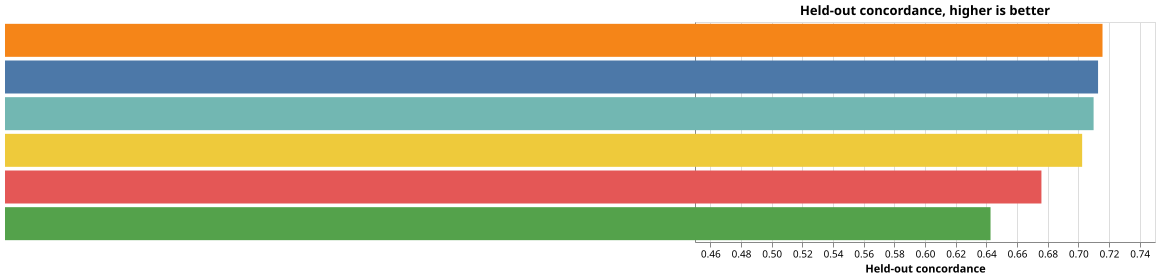

In [5]:
alt.Chart(summary).mark_bar().encode(
    x=alt.X("c_index:Q", title="Held-out concordance", scale=alt.Scale(domain=[0.45, 0.75])),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=460,
    height=220,
    title="Held-out concordance, higher is better",
)


## Results and interpretation

Quote the log-logistic, not the Weibull and not the regression that drops the censored patients. On the held-out patients its log-time score is {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Loglog')['nll'][0]):.3f}"` nats per patient and its concordance is {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Loglog')['c_index'][0]):.3f}"`. The Weibull is next, at {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Weibull')['nll'][0]):.3f}"` nats and concordance {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Weibull')['c_index'][0]):.3f}"`. The lognormal is clearly worse, {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Lognormal')['nll'][0]):.3f}"` nats. A log-logistic hazard rises and then falls, which is the shape this sample supports over a monotone Weibull. The gap is small on 57 patients. It is still the fit that wins both columns, so it is the one to quote.

The deaths-only regression scores {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS on deaths')['nll'][0]):.3f}"`. It never saw the patients who were still alive. Do not use it.

The Cox models rank about as well as the Weibull: concordance {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels PHReg')['c_index'][0]):.3f}"` for the partial-likelihood fit and {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost CoxPH')['c_index'][0]):.3f}"` for the boost. They have no log-time score because a partial likelihood is not a distribution of days. Use Cox only if the clinic needs an ordering and not a time. For a man at the sample's median age with ECOG 1, the log-logistic median is {eval}`f"{loglog_median_days:.0f}"` days. That is a fitted survival time, not a promise.

The Cox log-hazard coefficient on female is {eval}`f"{float(phreg.params[1]):.2f}"`, and on ECOG it is {eval}`f"{float(phreg.params[2]):.2f}"`. Women have the lower hazard. A one-point worse ECOG score raises it. Age is {eval}`f"{float(phreg.params[0]):.3f}"` per year. These are associations in one trial of advanced lung cancer, not effects of changing a score.

None of the boosts stopped at the step cap. Fifty-seven held-out patients is a small confirmation, not a second trial. A censored patient is alive at last contact, not a death on that day.


In [6]:
probe = boosted["mboostrs glmboost Weibull"]["fit"]
mu = np.asarray(probe.predict(fit_rows, type="link"), dtype=float).ravel()
sig = float(np.asarray(probe.nuisance()).ravel()[0])
z = (np.log(fit_rows["time"].to_numpy()) - mu) / sig
event = fit_rows["event"].to_numpy()
scipy_ll = float(np.sum(event * (np.log(1.0 / sig) + z - np.exp(z)) + (1.0 - event) * (-np.exp(z))))
weibull_ll_gap = abs(float(probe.logLik()) - scipy_ll)
cox_nuisance = boosted["mboostrs glmboost CoxPH"]["fit"].nuisance()
print("weibull logLik gap", weibull_ll_gap, "scale", sig)
print("cox nuisance", cox_nuisance)
print("weibull median days", round(weibull_median_days, 1))


weibull logLik gap 5.684341886080802e-14 scale 0.7354870568217787
cox nuisance None
weibull median days 282.0


## API behavior and limitations

`Surv(time, event)` wants `event` equal to 1 for a death and 0 for a censored time. The file's `status` is the other way round: 2 is a death. Using `status` as the event indicator swaps the deaths and the censored patients.

For the Weibull, `predict(type="link")` is the location of log days, and `nuisance()` is the extreme-value scale. The censored log likelihood with `z = (log(time) - location) / scale` matches `logLik()` to {eval}`f"{weibull_ll_gap:.1e}"`. `type="response"` is not that location. The median used above solves `exp(-exp(z)) = 1/2`.

`CoxPH.nuisance()` is an empty array. There is no scale to read. `predict(type="link")` is a log hazard ratio, so a larger value is a shorter survival, the opposite sign from the accelerated-failure-time location. Concordance for the Cox rows uses that link. Concordance for the parametric rows uses its negative.

The deaths-only regression is an ordinary least squares fit of log days. Scoring it with a censored lognormal likelihood does not put the censored patients back into the fit. It only shows what that fit is worth once they are counted.
